# Análise estatística exploratória da frota | AutoData Quality

**Objetivo.** Complementar o projeto AutoData Quality com uma camada estatística sobre os **dados reais** da frota (SENATRAN, jul/2026, recorte de São José dos Campos/SP): distribuições, outliers, correlações e normalização. As conclusões descrevem **este recorte**, não o mercado inteiro.

**Como usar.** `pip install -r requirements.txt`, abra no Jupyter e execute as células em ordem. A primeira seção reproduz as conferências já feitas no Excel; se ela passar, o restante usa os mesmos dados.

**Estrutura:** 1 carga e conferência · 2 distribuições (caminho 1) · 3 padronização e outliers (caminho 2) · 4 correlações (caminho 4) · 5 normalização · 6 exportação para Excel · 7 limitações e como repetir com outra região.

**Arquivos de entrada** (pasta `dados/`): `frota_sao_jose_dos_campos.csv` (as 5 colunas do arquivo da SENATRAN, uma linha por marca/modelo e ano de fabricação) e `veiculos_classificados.csv` (cadastro de veículos do projeto, com `Tipo_Veiculo` classificado manualmente).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

# ---------- Parâmetros: mude aqui para repetir com outra região ----------
ARQ_FROTA = Path("dados/frota_sao_jose_dos_campos.csv")      # recorte da frota (5 colunas, como no Excel)
ARQ_VEICULOS = Path("dados/veiculos_classificados.csv")      # cadastro de veículos com Tipo_Veiculo
ANO_REF = 2026            # ano da fonte (SENATRAN, jul/2026)
ANO_MIN_PROJETO = 1970    # piso adotado no projeto (P_AnoMin)
VERIFICAR_SJC = True      # True só para o recorte de São José dos Campos (liga as conferências)

PASTA_FIG, PASTA_RES = Path("figuras"), Path("resultados")
PASTA_FIG.mkdir(exist_ok=True); PASTA_RES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3})
resultados = {}   # tabelas que serão exportadas para o Excel no final

## 1. Carga e conferência

Lemos tudo como **texto** (`dtype=str`) e convertemos depois. Motivo: no Excel em português, `1.0` vira `10` se a conversão usar a localidade errada. Em Python a conversão é independente da localidade. O ano com o texto `Sem Informação` vira `NaN` em vez de derrubar a leitura.

In [2]:
# dtype=str: lemos tudo como texto e convertemos nós mesmos (evita o erro "1.0" -> 10 da localidade do Excel)
df = pd.read_csv(ARQ_FROTA, sep=";", dtype=str, encoding="utf-8-sig")
for c in df.columns:
    df[c] = df[c].str.strip()                      # tira espaços nas pontas (a fonte traz " 1.0")

df["qtd"] = pd.to_numeric(df["Qtd_Veiculos"], errors="coerce")        # "1.0" -> 1.0, independente da localidade
df["ano"] = pd.to_numeric(df["Ano_Fabricacao"], errors="coerce")      # "Sem Informação" -> NaN (não derruba a leitura)

TOTAL = df["qtd"].sum()
conf = pd.DataFrame({
    "item": ["linhas", "veículos (soma da quantidade)", "linhas com ano não numérico",
             "veículos nessas linhas", "modelos distintos (Marca_Modelo)", "linhas sem '/' (só a marca)"],
    "valor": [len(df), int(TOTAL), int(df["ano"].isna().sum()),
              int(df.loc[df["ano"].isna(), "qtd"].sum()), df["Marca_Modelo"].nunique(),
              int((~df["Marca_Modelo"].str.contains("/")).sum())]})
display(conf)

if VERIFICAR_SJC:   # mesmos números conferidos no Excel
    assert len(df) == 30671 and int(TOTAL) == 523100
    assert df["ano"].isna().sum() == 543 and df["Marca_Modelo"].nunique() == 10144
    assert (~df["Marca_Modelo"].str.contains("/")).sum() == 199
    print("OK: o notebook reproduz as conferências feitas no Excel.")

,item,valor
0,linhas,30671
1,veículos (soma da quantidade),523100
2,linhas com ano não numérico,543
3,veículos nessas linhas,2060
4,modelos distintos (Marca_Modelo),10144
5,linhas sem '/' (só a marca),199


OK: o notebook reproduz as conferências feitas no Excel.


**Leitura.** Os números batem com os do Excel (30.671 linhas, 523.100 veículos, 543 linhas com ano não numérico, 10.144 modelos, 199 linhas sem modelo). Isso valida a carga antes de qualquer estatística.

## 2. Caminho 1: distribuições da frota real

Cada linha do arquivo vale **N veículos**. Para usar as funções estatísticas comuns, expandimos cada linha em N valores de ano (`np.repeat`). Conceitos usados: **média x mediana** (a média é puxada por valores extremos), **percentis** (o ano abaixo do qual está p% da frota), **assimetria** (negativa = cauda longa de valores baixos, aqui anos antigos).

In [3]:
# Truque didático: "expandir" cada linha em N veículos, para usar as funções estatísticas comuns.
# (523 mil valores cabem tranquilamente na memória.)
validos = df.dropna(subset=["ano"])
anos = np.repeat(validos["ano"].to_numpy(), validos["qtd"].astype(int).to_numpy())
idade = ANO_REF - anos

pct = {p: np.percentile(anos, p) for p in (0.5, 1, 5, 25, 50, 75, 95, 99)}
tab = pd.DataFrame({
    "estatística": ["veículos com ano válido", "média (ano)", "mediana (ano)", "desvio padrão (anos)",
                    "assimetria (skew)", "curtose (excesso)", "P0,5", "P1", "P5", "P25", "P50", "P75", "P95", "P99",
                    "idade média", "idade mediana", "idade P90"],
    "valor": [len(anos), anos.mean(), np.median(anos), anos.std(ddof=1), stats.skew(anos), stats.kurtosis(anos),
              *pct.values(), idade.mean(), np.median(idade), np.percentile(idade, 90)]}).round(2)
resultados["distribuicao_ano"] = tab
display(tab)

,estatística,valor
0,veículos com ano válido,521040.00
1,média (ano),2006.75
2,mediana (ano),2009.00
3,desvio padrão (anos),12.83
4,assimetria (skew),-0.77
5,curtose (excesso),0.19
6,"P0,5",1970.00
7,P1,1973.00
8,P5,1981.00
9,P25,1998.00


**Leitura (recorte de São José dos Campos).** A mediana do ano de fabricação é **2009** e a média **2006,75**: a média fica abaixo da mediana porque há uma cauda de veículos antigos (assimetria **-0,77**). A idade mediana é **17 anos**; 10% dos veículos têm 38 anos ou mais. 2.060 veículos (0,39%) ficaram de fora por ano não numérico.

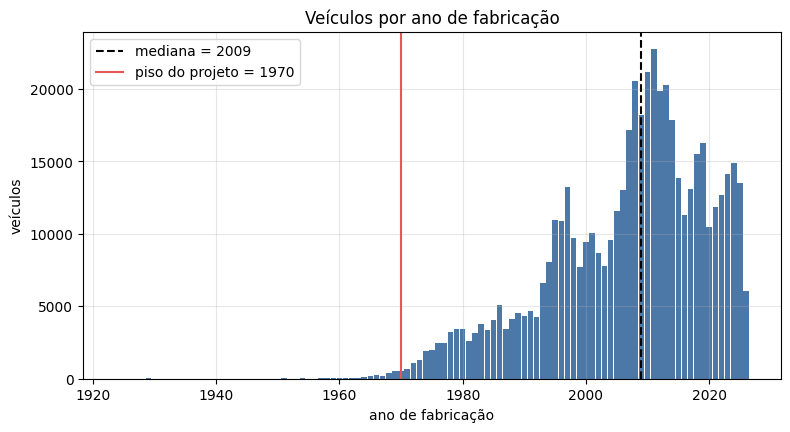

In [4]:
contagem = pd.Series(anos).value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(contagem.index, contagem.values, width=0.9, color="#4C78A8")
ax.axvline(np.median(anos), color="black", ls="--", label=f"mediana = {int(np.median(anos))}")
ax.axvline(ANO_MIN_PROJETO, color="#E45756", ls="-", label=f"piso do projeto = {ANO_MIN_PROJETO}")
ax.set(title="Veículos por ano de fabricação", xlabel="ano de fabricação", ylabel="veículos"); ax.legend()
fig.savefig(PASTA_FIG / "01_distribuicao_ano.png", dpi=150, bbox_inches="tight"); plt.show()

,antes de,veículos,% da frota (como no Excel),% dos veículos com ano válido
0,1950,76,0.01,0.01
1,1960,255,0.05,0.05
2,1970,2166,0.41,0.42
3,1980,21342,4.08,4.10


Percentil em que o piso de 1970 cai: 0.42


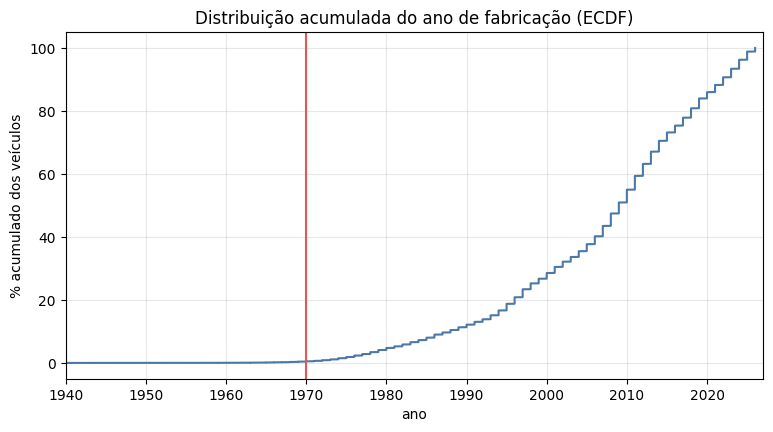

In [5]:
# Mesma conta feita no Excel (denominador = TODOS os veículos, inclusive os de ano não numérico)
cortes = pd.DataFrame({"antes de": [1950, 1960, 1970, 1980]})
cortes["veículos"] = [int((anos < c).sum()) for c in cortes["antes de"]]
cortes["% da frota (como no Excel)"] = (100 * cortes["veículos"] / TOTAL).round(2)
cortes["% dos veículos com ano válido"] = (100 * cortes["veículos"] / len(anos)).round(2)
resultados["cortes_de_ano"] = cortes
display(cortes)
print(f"Percentil em que o piso de {ANO_MIN_PROJETO} cai: {100 * (anos < ANO_MIN_PROJETO).mean():.2f}")

x = np.sort(anos); y = np.arange(1, len(x) + 1) / len(x)       # função de distribuição empírica (ECDF)
fig, ax = plt.subplots()
ax.plot(x, 100 * y, color="#4C78A8"); ax.axvline(ANO_MIN_PROJETO, color="#E45756")
ax.set(title="Distribuição acumulada do ano de fabricação (ECDF)", xlabel="ano", ylabel="% acumulado dos veículos")
ax.set_xlim(1940, 2027); fig.savefig(PASTA_FIG / "02_ecdf_ano.png", dpi=150, bbox_inches="tight"); plt.show()

**Leitura.** A tabela reproduz os cortes calculados no Excel (0,01%, 0,05%, 0,41% e 4,08%). O piso de **1970** escolhido no projeto corresponde ao **percentil 0,42** da frota: só 0,42% dos veículos são mais antigos. Até aqui a escolha foi por cobertura; a seção 3 testa se critérios estatísticos chegam perto dela.

**Concentração (cauda longa).** Quantos modelos são necessários para explicar a frota? A **curva de cobertura** e o **coeficiente de Gini** (0 = todos os modelos com o mesmo volume; 1 = tudo em um só) resumem isso.

,medida,valor
0,modelos distintos,10144
1,cobertura dos 250 mais frequentes,47.26%
2,modelos para 50% da frota,288
3,modelos para 80% da frota,1239
4,modelos para 90% da frota,2285
5,modelos com apenas 1 veículo,2286
6,% dos modelos com apenas 1 veículo,22.5%
7,coeficiente de Gini,0.84


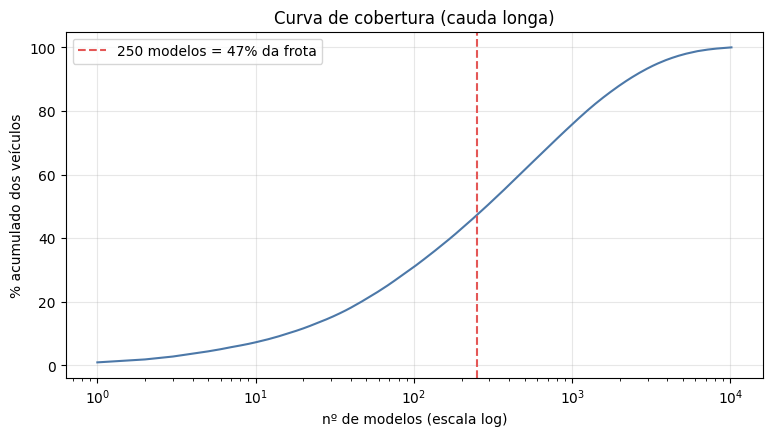

In [6]:
por_modelo = df.groupby("Marca_Modelo")["qtd"].sum().sort_values(ascending=False)
acum = por_modelo.cumsum() / por_modelo.sum()
n_para = lambda p: int((acum < p).sum() + 1)          # quantos modelos são necessários para cobrir p% da frota

def gini(valores):                                     # 0 = tudo igual; 1 = tudo concentrado em um só
    v = np.sort(np.asarray(valores, dtype=float)); n = len(v)
    return (n + 1 - 2 * np.sum(np.cumsum(v)) / v.sum()) / n

conc = pd.DataFrame({
    "medida": ["modelos distintos", "cobertura dos 250 mais frequentes", "modelos para 50% da frota",
               "modelos para 80% da frota", "modelos para 90% da frota", "modelos com apenas 1 veículo",
               "% dos modelos com apenas 1 veículo", "coeficiente de Gini"],
    "valor": [len(por_modelo), f"{100 * acum.iloc[249]:.2f}%", n_para(.5), n_para(.8), n_para(.9),
              int((por_modelo == 1).sum()), f"{100 * (por_modelo == 1).mean():.1f}%", round(gini(por_modelo), 3)]})
resultados["concentracao"] = conc
display(conc)

fig, ax = plt.subplots()
ax.plot(np.arange(1, len(acum) + 1), 100 * acum.values, color="#4C78A8"); ax.set_xscale("log")
ax.axvline(250, color="#E45756", ls="--", label=f"250 modelos = {100 * acum.iloc[249]:.0f}% da frota"); ax.legend()
ax.set(title="Curva de cobertura (cauda longa)", xlabel="nº de modelos (escala log)", ylabel="% acumulado dos veículos")
fig.savefig(PASTA_FIG / "03_cobertura_modelos.png", dpi=150, bbox_inches="tight"); plt.show()

**Leitura.** A frota do recorte é muito concentrada: **288 modelos** explicam metade dos veículos e **1.239** explicam 80%, num total de 10.144. O Gini de **0,84** confirma a concentração, e **22,5% dos modelos têm um único veículo** (cauda longa). Por isso os 250 modelos mais frequentes escolhidos no projeto cobrem **47%** da frota, e mais de 2.000 modelos seriam necessários para chegar perto de 90%.

## 3. Caminho 2: padronização e outliers

**Padronização.** Reaplicamos em Python a regra do Excel: separar marca e modelo no primeiro `/`, tratar os prefixos de origem (`I`, `IMP`, `JTA`, `REB`, `SR`: a marca real é a primeira palavra do modelo) e unificar marcas (`GM`/`CHEV` viram `CHEVROLET`, `VW` vira `VOLKSWAGEN`). Limitação conhecida: marcas com duas palavras (por exemplo, `LAND ROVER`) ficam só com a primeira quando vêm após um prefixo.

In [7]:
# Reaplica em Python a padronização feita no Excel/Power Query (marca/modelo, prefixos, De->Para de marcas)
PREFIXOS = {"I", "IMP", "JTA", "REB", "SR"}                    # códigos de origem antes da marca (achados na fonte)
DEPARA_MARCA = {"VW": "VOLKSWAGEN", "GM": "CHEVROLET", "CHEV": "CHEVROLET"}

def padronizar(marca_modelo):
    s = " ".join(str(marca_modelo).split()).upper()
    if "/" not in s:                                           # só a marca, sem modelo
        return s, ""
    marca, modelo = [p.strip() for p in s.split("/", 1)]
    if marca in PREFIXOS:                                      # a marca real é a 1ª palavra do modelo
        partes = modelo.split(" ", 1)
        marca, modelo = partes[0], (partes[1] if len(partes) > 1 else "")
    return DEPARA_MARCA.get(marca, marca), " ".join(modelo.split())

# aplicamos só nos 10 mil textos distintos (rápido) e juntamos de volta
u = pd.DataFrame({"Marca_Modelo": df["Marca_Modelo"].unique()})
u[["marca", "modelo"]] = u["Marca_Modelo"].apply(lambda s: pd.Series(padronizar(s)))
u["chave"] = u["marca"] + "|" + u["modelo"]
df = df.merge(u, on="Marca_Modelo", how="left")

veic = pd.read_csv(ARQ_VEICULOS, sep=";", encoding="utf-8-sig")
df = df.merge(veic[["Chave_Modelo", "Tipo_Veiculo"]].drop_duplicates("Chave_Modelo"),
              left_on="chave", right_on="Chave_Modelo", how="left")
df["marca_bruta"] = df["Marca_Modelo"].str.split("/").str[0]
prefixados = df["marca_bruta"].isin(PREFIXOS)

norm = pd.DataFrame({
    "medida": ["textos distintos de Marca_Modelo", "modelos distintos após padronizar (chave marca|modelo)",
               "redução de cardinalidade", "linhas com prefixo de origem", "% dos veículos com prefixo de origem",
               "% dos veículos com Tipo_Veiculo classificado"],
    "valor": [len(u), u["chave"].nunique(), f"{100 * (1 - u['chave'].nunique() / len(u)):.1f}%",
              int(prefixados.sum()), f"{100 * df.loc[prefixados, 'qtd'].sum() / TOTAL:.1f}%",
              f"{100 * df.loc[df['Tipo_Veiculo'].notna(), 'qtd'].sum() / TOTAL:.1f}%"]})
resultados["normalizacao_cardinalidade"] = norm
display(norm)

# conferência: os modelos que o Excel classificou devem ser encontrados pela padronização em Python
chaves_ok = veic["Chave_Modelo"].isin(df["chave"]).mean()
print(f"{100 * chaves_ok:.1f}% das chaves do cadastro de veículos foram reencontradas pela padronização em Python")

,medida,valor
0,textos distintos de Marca_Modelo,10144
1,modelos distintos após padronizar (chave marca...,9936
2,redução de cardinalidade,2.1%
3,linhas com prefixo de origem,9536
4,% dos veículos com prefixo de origem,12.5%
5,% dos veículos com Tipo_Veiculo classificado,47.6%


100.0% das chaves do cadastro de veículos foram reencontradas pela padronização em Python


**Leitura.** A padronização reduz os 10.144 textos distintos a **9.936 modelos** (-2,1%). O dado mais relevante é outro: **12,5% dos veículos** vêm com prefixo de origem (**31% das linhas**), muito mais do que os poucos casos vistos na amostra de 250 modelos. Sem esse tratamento, essas linhas ficariam com uma "marca" que não é marca. O cadastro de veículos do projeto foi **reencontrado integralmente** pela padronização em Python (100% das chaves), e 47,6% dos veículos têm tipo classificado.

**Outliers com critério robusto.** Um outlier não é um erro: é um valor atípico em relação à distribuição. Dois critérios comuns: **cerca de Tukey** (abaixo de Q1 - 1,5 x IQR, onde IQR = Q3 - Q1) e **escore z robusto** com a **MAD** (desvio absoluto mediano, que quase não é afetado por extremos). Comparamos os dois com o piso fixo do projeto.

Q1=1998  Q3=2016  IQR=18  mediana=2009  MAD=9


,critério,ano de corte,veículos abaixo do corte,% da frota com ano válido
0,piso fixo do projeto (1970),1970.0,2166,0.42
1,"cerca de Tukey (Q1 - 1,5*IQR)",1971.0,2730,0.52
2,"MAD robusto (z > 3,5)",1962.3,428,0.08


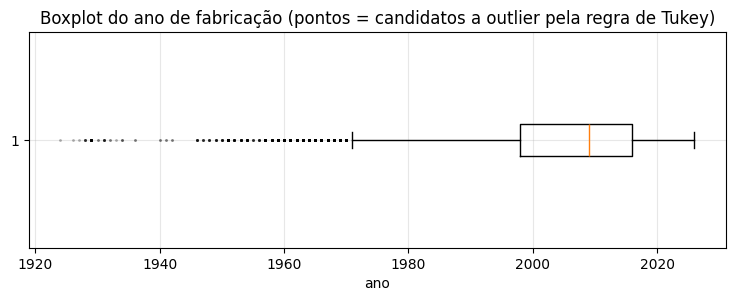

In [8]:
# Dois critérios estatísticos robustos para "ano atípico", comparados com o piso fixo do projeto
q1, q3 = np.percentile(anos, [25, 75]); iqr = q3 - q1
cerca_tukey = q1 - 1.5 * iqr                                   # cerca inferior de Tukey (IQR)
med = np.median(anos); mad = np.median(np.abs(anos - med))     # mediana e MAD (desvio absoluto mediano)
limite_mad = med - 3.5 * 1.4826 * mad                          # escore z robusto > 3,5 (1,4826 ~ ajusta o MAD ao desvio padrão)

crit = pd.DataFrame({"critério": [f"piso fixo do projeto ({ANO_MIN_PROJETO})", "cerca de Tukey (Q1 - 1,5*IQR)", "MAD robusto (z > 3,5)"],
                     "ano de corte": [ANO_MIN_PROJETO, round(cerca_tukey, 1), round(limite_mad, 1)]})
crit["veículos abaixo do corte"] = [int((anos < c).sum()) for c in crit["ano de corte"]]
crit["% da frota com ano válido"] = (100 * crit["veículos abaixo do corte"] / len(anos)).round(2)
resultados["outliers_globais"] = crit
print(f"Q1={q1:.0f}  Q3={q3:.0f}  IQR={iqr:.0f}  mediana={med:.0f}  MAD={mad:.0f}")
display(crit)

fig, ax = plt.subplots(figsize=(9, 2.8))
ax.boxplot(anos, vert=False, whis=1.5, flierprops=dict(marker=".", markersize=2, alpha=.3))
ax.set(title="Boxplot do ano de fabricação (pontos = candidatos a outlier pela regra de Tukey)", xlabel="ano")
fig.savefig(PASTA_FIG / "04_boxplot_ano.png", dpi=150, bbox_inches="tight"); plt.show()

**Leitura.** A cerca de Tukey cai no ano **1971**, praticamente o piso de **1970** escolhido por cobertura (0,52% x 0,42% dos veículos). O critério MAD é mais permissivo (corte em 1962; 0,08%). Ou seja, o piso fixo tem apoio estatístico, e não é arbitrário.

In [9]:
# O que é "atípico" depende do tipo de veículo. Só temos Tipo_Veiculo nos modelos classificados no projeto.
t = validos.merge(df[["Marca_Modelo", "Tipo_Veiculo"]].drop_duplicates(), on="Marca_Modelo", how="left").dropna(subset=["Tipo_Veiculo"])
linhas = []
for tipo, g in t.groupby("Tipo_Veiculo"):
    a = np.repeat(g["ano"].to_numpy(), g["qtd"].astype(int).to_numpy())
    q1t, q3t = np.percentile(a, [25, 75]); mt = np.median(a); madt = max(np.median(np.abs(a - mt)), 1)
    cerca_t = q1t - 1.5 * (q3t - q1t); lim_t = mt - 3.5 * 1.4826 * madt
    linhas.append({"tipo": tipo, "veículos": len(a), "mediana": mt, "Q1": q1t, "Q3": q3t,
                   "cerca de Tukey": round(cerca_t, 1), "corte MAD": round(lim_t, 1),
                   f"abaixo de {ANO_MIN_PROJETO}": int((a < ANO_MIN_PROJETO).sum()),
                   "abaixo da cerca de Tukey": int((a < cerca_t).sum()),
                   "% abaixo da cerca": round(100 * (a < cerca_t).mean(), 2)})
por_tipo = pd.DataFrame(linhas); resultados["outliers_por_tipo"] = por_tipo
display(por_tipo)

,tipo,veículos,mediana,Q1,Q3,cerca de Tukey,corte MAD,abaixo de 1970,abaixo da cerca de Tukey,% abaixo da cerca
0,Motocicleta,47058,2008.0,2004.0,2017.0,1984.5,1982.1,0,664,1.41
1,Passeio,188347,2007.0,1996.0,2013.0,1970.5,1965.5,1240,1639,0.87
2,Reboque/Implemento,1115,2010.0,2006.0,2014.0,1994.0,1989.2,0,1,0.09
3,Utilitário leve,11536,2007.0,1995.0,2012.0,1969.5,1970.7,36,36,0.31


**Leitura.** O que é atípico muda com o tipo de veículo. Para **passeio**, a cerca de Tukey fica em 1970,5, igual ao piso. Para **motocicleta**, fica em **1984,5**: nenhuma moto é anterior a 1970, então o piso fixo **não pega nada**, mas 664 motos (1,41%) estão abaixo da cerca estatística. Um piso único é uma simplificação; uma regra por tipo seria mais precisa. Atenção: estes números valem para os modelos classificados (os mais frequentes), e não para toda a frota. Reboque tem poucos veículos para uma conclusão.

In [10]:
# Outlier "dentro do modelo": um ano muito distante do que o próprio modelo costuma ter.
def mediana_ponderada(x, w):
    i = np.argsort(x); x, w = x[i], w[i]; c = np.cumsum(w)
    return x[np.searchsorted(c, c[-1] / 2)]

MIN_ANOS, MIN_VEIC, Z_CORTE, DESVIO_MIN = 8, 30, 3.5, 10      # critérios mínimos para avaliar e para sinalizar
sinalizados, avaliados = [], 0
for chave, g in df.dropna(subset=["ano"]).groupby("chave"):
    if g["ano"].nunique() < MIN_ANOS or g["qtd"].sum() < MIN_VEIC or chave.endswith("|"):
        continue
    avaliados += 1
    x, w = g["ano"].to_numpy(), g["qtd"].to_numpy()
    med_m = mediana_ponderada(x, w); mad_m = max(mediana_ponderada(np.abs(x - med_m), w), 1.0)
    z = np.abs(x - med_m) / (1.4826 * mad_m)
    m = (z > Z_CORTE) & (np.abs(x - med_m) >= DESVIO_MIN)
    if m.any():
        sinalizados.append(pd.DataFrame({"modelo": chave, "ano": x[m], "veículos": w[m], "mediana do modelo": med_m,
                                         "desvio (anos)": x[m] - med_m, "z robusto": z[m].round(1)}))
fora = pd.concat(sinalizados, ignore_index=True) if sinalizados else pd.DataFrame()
passa_piso = fora[fora["ano"] >= ANO_MIN_PROJETO] if len(fora) else fora

resumo_m = pd.DataFrame({
    "medida": ["modelos avaliados", "pares modelo-ano sinalizados", "veículos sinalizados",
               "% dos veículos com ano válido", f"sinalizados que o piso de {ANO_MIN_PROJETO} NÃO pega (ano >= piso)"],
    "valor": [avaliados, len(fora), int(fora["veículos"].sum()), f"{100 * fora['veículos'].sum() / len(anos):.2f}%",
              f"{len(passa_piso)} pares / {int(passa_piso['veículos'].sum())} veículos"]})
resultados["outliers_por_modelo_resumo"] = resumo_m
resultados["outliers_por_modelo_top"] = fora.sort_values("veículos", ascending=False).head(25)
display(resumo_m)
display(fora.sort_values("veículos", ascending=False).head(10))

,medida,valor
0,modelos avaliados,482
1,pares modelo-ano sinalizados,185
2,veículos sinalizados,794
3,% dos veículos com ano válido,0.15%
4,sinalizados que o piso de 1970 NÃO pega (ano >...,152 pares / 739 veículos


,modelo,ano,veículos,mediana do modelo,desvio (anos),z robusto
57,FIAT|PALIO FIRE,2015.0,91.0,2004.0,11.0,3.7
58,FIAT|PALIO FIRE,2016.0,59.0,2004.0,12.0,4.0
9,CHEVROLET|CHEVETTE L,1978.0,36.0,1993.0,-15.0,10.1
10,CHEVROLET|CHEVETTE L,1979.0,27.0,1993.0,-14.0,9.4
177,VOLKSWAGEN|SANTANA,1986.0,22.0,1999.0,-13.0,4.4
151,VOLKSWAGEN|FUSCA 1600,1976.0,21.0,1993.0,-17.0,3.8
170,VOLKSWAGEN|PASSAT,1995.0,21.0,1979.0,16.0,5.4
8,CHEVROLET|CHEVETTE L,1977.0,17.0,1993.0,-16.0,10.8
14,CHEVROLET|CHEVETTE L,1983.0,17.0,1993.0,-10.0,6.7
110,MMC|PAJERO SPORT HPE,2019.0,17.0,2008.0,11.0,7.4


**Leitura.** Dos 482 modelos avaliados, **185 pares modelo-ano** foram sinalizados (794 veículos, 0,15%), e **152 pares (739 veículos) estão acima do piso de 1970**: o corte fixo não os pegaria. Mas sinalizar não é reprovar. Os exemplos do topo parecem legítimos ou ambíguos, e não erros: um modelo que continuou sendo registrado fora da faixa típica de fabricação, ou um mesmo nome cobrindo gerações diferentes (como `PASSAT` e `PAJERO SPORT`). Essas são hipóteses que precisam de conhecimento do mercado para serem confirmadas. A conclusão prática é uma regra **de revisão** (um aviso para um analista olhar), não de rejeição automática.

## 4. Caminho 4: correlações

Usamos a **correlação de Spearman** (ordens, não valores: robusta a extremos) e comparamos distribuições com testes de hipótese. Lembre: **correlação não é causa**, e aqui é descritiva. Em amostras grandes, quase tudo é "estatisticamente significativo": olhe sempre o **tamanho do efeito**.

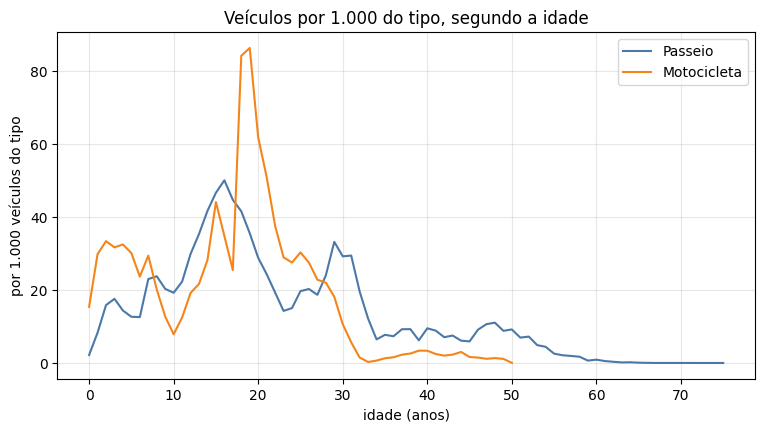

,tipo,idade do pico,Spearman (todas as idades),Spearman (do pico em diante),p (do pico em diante)
0,Passeio,16,-0.79,-0.94,4.1e-26
1,Motocicleta,19,-0.73,-0.81,1.8e-08


In [11]:
# Correlação 1: idade x quantidade em circulação, por tipo (só modelos classificados). Descritiva, não causal.
saida = []
fig, ax = plt.subplots()
for tipo, cor in (("Passeio", "#4C78A8"), ("Motocicleta", "#F58518")):
    g = t[t["Tipo_Veiculo"] == tipo].groupby("ano")["qtd"].sum()
    g.index = (ANO_REF - g.index).astype(int); g = g.sort_index()            # índice = idade
    por_mil = 1000 * g / g.sum()                                              # normalização: por 1.000 veículos do tipo
    idade_pico = int(por_mil.idxmax())
    depois = por_mil[por_mil.index >= idade_pico]                              # fase de "decaimento" (do pico em diante)
    r_all = stats.spearmanr(g.index, g.values); r_dec = stats.spearmanr(depois.index, depois.values)
    saida.append({"tipo": tipo, "idade do pico": idade_pico, "Spearman (todas as idades)": round(r_all.statistic, 2),
                  "Spearman (do pico em diante)": round(r_dec.statistic, 2), "p (do pico em diante)": f"{r_dec.pvalue:.1e}"})
    ax.plot(por_mil.index, por_mil.values, label=tipo, color=cor)
ax.set(title="Veículos por 1.000 do tipo, segundo a idade", xlabel="idade (anos)", ylabel="por 1.000 veículos do tipo"); ax.legend()
fig.savefig(PASTA_FIG / "05_idade_por_tipo.png", dpi=150, bbox_inches="tight"); plt.show()
corr_idade = pd.DataFrame(saida); resultados["correlacao_idade_tipo"] = corr_idade
display(corr_idade)

**Leitura.** Quanto mais velho o veículo, menos veículos desse ano existem **depois do pico**: Spearman de **-0,94** para passeio (pico aos 16 anos) e **-0,81** para motocicleta (pico aos 19 anos). A curva sobe até o pico e depois cai, por isso a correlação em todas as idades (-0,79 e -0,73) é menor. Não dá para separar quanto da queda é sucateamento e quanto é menor produção no passado: não temos dados de vendas.

,medida,valor
0,modelos,248
1,Spearman (faixa x volume),0.09
2,p-valor,1.5e-01
3,Pearson (faixa x log10 volume),0.1
4,p-valor,1.0e-01


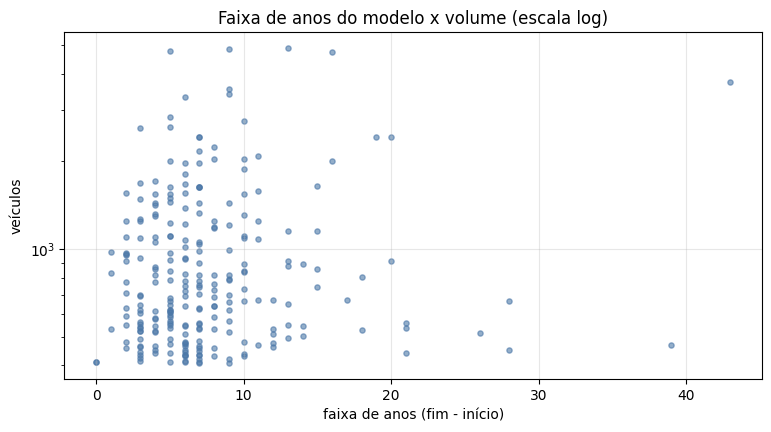

In [12]:
# Correlação 2: faixa de anos do modelo x volume (modelos do cadastro). ATENÇÃO ao viés de seleção.
vol = df.groupby("chave")["qtd"].sum()
v2 = veic.copy(); v2["volume"] = v2["Chave_Modelo"].map(vol)
v2["faixa"] = v2["Ano_Fim_Final"] - v2["Ano_Ini_Final"]; v2 = v2.dropna(subset=["volume", "faixa"])
sp = stats.spearmanr(v2["faixa"], v2["volume"]); pe = stats.pearsonr(v2["faixa"], np.log10(v2["volume"]))
corr_faixa = pd.DataFrame({"medida": ["modelos", "Spearman (faixa x volume)", "p-valor", "Pearson (faixa x log10 volume)", "p-valor"],
                           "valor": [len(v2), round(sp.statistic, 2), f"{sp.pvalue:.1e}", round(pe.statistic, 2), f"{pe.pvalue:.1e}"]})
resultados["correlacao_faixa_volume"] = corr_faixa; display(corr_faixa)

fig, ax = plt.subplots()
ax.scatter(v2["faixa"], v2["volume"], s=14, alpha=.6, color="#4C78A8"); ax.set_yscale("log")
ax.set(title="Faixa de anos do modelo x volume (escala log)", xlabel="faixa de anos (fim - início)", ylabel="veículos")
fig.savefig(PASTA_FIG / "06_faixa_volume.png", dpi=150, bbox_inches="tight"); plt.show()

**Leitura.** A correlação entre a **faixa de anos do modelo** e o seu volume é **fraca e não significativa** (Spearman 0,09, p = 0,15; n = 248). Cuidado ao interpretar: o cadastro tem os modelos **mais frequentes**, ou seja, a amostra foi escolhida pelo próprio volume (viés de seleção e restrição de faixa). O resultado é inconclusivo, e não prova que não existe relação.

In [13]:
# Duas distribuições são diferentes? Passeio x Motocicleta (ano de fabricação, nível de veículo)
a_p = np.repeat(t.loc[t["Tipo_Veiculo"] == "Passeio", "ano"].to_numpy(), t.loc[t["Tipo_Veiculo"] == "Passeio", "qtd"].astype(int).to_numpy())
a_m = np.repeat(t.loc[t["Tipo_Veiculo"] == "Motocicleta", "ano"].to_numpy(), t.loc[t["Tipo_Veiculo"] == "Motocicleta", "qtd"].astype(int).to_numpy())
ks = stats.ks_2samp(a_p, a_m); u_ = stats.mannwhitneyu(a_p, a_m, alternative="two-sided")
cliff = 2 * u_.statistic / (len(a_p) * len(a_m)) - 1          # delta de Cliff: tamanho do efeito (-1 a 1)
comp = pd.DataFrame({"medida": ["mediana Passeio", "mediana Motocicleta", "KS (estatística D)", "KS p-valor",
                                "Mann-Whitney p-valor", "delta de Cliff (Passeio vs Moto)"],
                     "valor": [np.median(a_p), np.median(a_m), round(ks.statistic, 3), f"{ks.pvalue:.1e}", f"{u_.pvalue:.1e}", round(cliff, 3)]})
resultados["comparacao_passeio_moto"] = comp; display(comp)

,medida,valor
0,mediana Passeio,2007.0
1,mediana Motocicleta,2008.0
2,KS (estatística D),0.232
3,KS p-valor,0.0e+00
4,Mann-Whitney p-valor,0.0e+00
5,delta de Cliff (Passeio vs Moto),-0.212


**Leitura.** As medianas de ano são parecidas (2007 x 2008), mas as distribuições **não são iguais** (KS D = 0,232). O p-valor aparece como 0,0 por limite numérico (é menor que 1e-300): com 235 mil veículos, qualquer diferença é "significativa". O que importa é o **tamanho do efeito**: delta de Cliff de **-0,21**, efeito **pequeno**, no sentido de passeios serem em geral mais antigos que motos.

## 5. Normalização e padronização estatística

Para **comparar curvas de tamanhos diferentes** (passeio x moto, ou duas cidades), normalizamos: **por 1.000** (cada ano como parcela do total do tipo), **z-score** (quantos desvios padrão acima ou abaixo da média: média 0 e desvio 1) e **min-max** (escala de 0 a 1). Cada uma responde a uma pergunta diferente: proporção, posição relativa e forma da curva.

In [14]:
# Normalização para comparar curvas de tamanhos diferentes: "por 1.000" e z-score por tipo.
def zscore(s): return (s - s.mean()) / s.std(ddof=1)
def minmax(s): return (s - s.min()) / (s.max() - s.min())

tab_norm = {}
for tipo in ("Passeio", "Motocicleta"):
    g = t[t["Tipo_Veiculo"] == tipo].groupby("ano")["qtd"].sum().sort_index()
    tab_norm[tipo] = pd.DataFrame({"veículos": g, "por 1.000": (1000 * g / g.sum()).round(1),
                                   "z-score": zscore(g).round(2), "min-max": minmax(g).round(3)})
exemplo = tab_norm["Passeio"].loc[[2000, 2010, 2020]]
display(exemplo)
print("Média do z-score ≈ 0 e desvio ≈ 1:", round(zscore(tab_norm['Passeio']['veículos']).mean(), 6), round(zscore(tab_norm['Passeio']['veículos']).std(ddof=1), 6))
resultados["normalizacao_exemplo_passeio"] = tab_norm["Passeio"].reset_index().tail(30)

,veículos,por 1.000,z-score,min-max
ano,,,,
2000.0,3817.0,20.3,0.48,0.405
2010.0,9424.0,50.0,2.79,1.000
2020.0,2367.0,12.6,-0.12,0.251


Média do z-score ≈ 0 e desvio ≈ 1: -0.0 1.0


**Leitura.** O ano 2010 tem **5,0%** dos passeios classificados e z-score de **+2,79** (pico); 2020 está abaixo da média (z = -0,12). A conferência (média 0, desvio 1) confirma a conta.

## 6. Exportação para o Excel

O Excel é a ferramenta final de entrega: as tabelas deste notebook são gravadas em `resultados/resumo_estatistico.xlsx` e as figuras em `figuras/`.

In [15]:
saida_xlsx = PASTA_RES / "resumo_estatistico.xlsx"
with pd.ExcelWriter(saida_xlsx, engine="openpyxl") as xw:
    for nome, tabela in resultados.items():
        tabela.to_excel(xw, sheet_name=nome[:31], index=False)
print("Excel gerado:", saida_xlsx)
print("Figuras:", sorted(p.name for p in PASTA_FIG.glob("*.png")))

Excel gerado: resultados/resumo_estatistico.xlsx
Figuras: ['01_distribuicao_ano.png', '02_ecdf_ano.png', '03_cobertura_modelos.png', '04_boxplot_ano.png', '05_idade_por_tipo.png', '06_faixa_volume.png']


## 7. Limitações e como repetir com outra região

**Limitações.**
- Um município; as conclusões não se estendem ao Brasil nem ao mercado.
- Tipo de veículo só existe nos modelos classificados no projeto (os mais frequentes), o que enviesa as análises por tipo.
- O ano é o de fabricação dos veículos em circulação; a frota não informa o período oficial de produção de cada modelo.
- Outlier é sinal para revisão, não prova de erro. Os critérios (1,5 x IQR, z > 3,5, desvio mínimo de 10 anos) são escolhas, e outros valores dariam outros números.

**Para repetir com outra região**, só mude a seção de parâmetros no início:
1. Gere um CSV com as mesmas 5 colunas (`UF`, `Municipio`, `Marca_Modelo`, `Ano_Fabricacao`, `Qtd_Veiculos`) para o município escolhido e salve em `dados/`.
2. Aponte `ARQ_FROTA` para o novo arquivo e coloque `VERIFICAR_SJC = False` (as conferências 30.671 / 523.100 valem só para São José dos Campos).
3. Os tipos (`Tipo_Veiculo`) só existem para os modelos já classificados; em outra cidade a cobertura será menor, e isso aparece na seção 3. Para ampliar, classifique mais modelos.
4. Execute tudo e compare os resultados com os de São José dos Campos.